In [4]:
import pandas as pd
odf = pd.read_csv("new_pose_detection/data/angela_final.csv",index_col = 0)
odf

,Frame,time_sec,angle_1_deg,angle_2_deg,angle_3_deg,angle_4_deg,angle_5_deg,angle_6_deg,angular_velocity_1_deg_per_s,angular_velocity_2_deg_per_s,...,rom_1s_angle_2_deg,rom_1s_angle_3_deg,rom_1s_angle_4_deg,rom_1s_angle_5_deg,rom_1s_angle_6_deg,symmetry_absdiff_angle_1_vs_2_deg,symmetry_absdiff_angle_3_vs_4_deg,symmetry_absdiff_angle_5_vs_6_deg,LDF_bloodflow,AMI_bloodflow
0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,329.4,2882.0
1,30.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,283.0,2856.0
2,60.0,2.0,164.021046,123.369079,44.181805,47.711020,100.245778,169.808967,NaN,NaN,...,0.000000,0.000000,0.000000,0.000000,0.000000,40.651967,3.529215,69.563189,281.7,2927.0
3,90.0,3.0,116.330037,169.419731,128.695684,45.971520,156.082712,165.963855,-47.691009,46.050652,...,46.050652,84.513879,1.739500,55.836934,3.845111,53.089694,82.724164,9.881143,281.8,2883.0
4,120.0,4.0,98.205633,174.281623,79.168880,22.520089,153.409185,160.233055,-18.124405,4.861891,...,4.861891,49.526804,23.451431,2.673527,5.730800,76.075990,56.648791,6.823870,371.5,2902.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
580,17400.0,580.0,148.514565,144.260453,43.485040,47.251849,134.711424,165.379642,1.525054,-2.060458,...,2.060458,13.958748,13.243384,9.059212,8.985057,4.254113,3.766809,30.668218,NaN,NaN
581,17430.0,581.0,147.969090,148.541761,46.404863,43.940903,148.662120,162.311315,-0.545476,4.281308,...,4.281308,2.919823,3.310947,13.950697,3.068327,0.572671,2.463960,13.649194,NaN,NaN
582,17460.0,582.0,149.489351,146.792047,42.706668,45.711899,157.714770,159.412908,1.520261,-1.749715,...,1.749715,3.698195,1.770996,9.052650,2.898407,2.697304,3.005231,1.698138,NaN,NaN
583,17490.0,583.0,148.000087,147.389677,42.328663,40.341920,145.970854,151.797334,-1.489264,0.597630,...,0.597630,0.378005,5.369980,11.743916,7.615574,0.610410,1.986744,5.826480,NaN,NaN


In [5]:
#Make a copy of odf
df = odf.copy()
#Change shift 0 to shift1, shift2, ... shift 10 if it wasn't accurate
df['LDF_bloodflow'] = df['LDF_bloodflow'].shift(-20)
#Removes rows with NaN values that would prevent machine learning
df = df.dropna()

In [6]:

#Example of Simplest Machine Learnign Code
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

#X = Everything other than LDF bloodflow
X = df.drop(columns=['LDF_bloodflow'])
#y = LDF bloodflow
y = df['LDF_bloodflow']

#Splitting Data into Train and Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](30,)","[ 0.01, 0. ,-0.73,..., 0.65, 0.86, 0.26]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['Frame','time_sec','angle_1_deg',...,'symmetry_absdiff_angle_3_vs_4_deg', 'symmetry_absdiff_angle_5_vs_6_deg','AMI_bloodflow']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-534.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(26)


In [7]:
#Example of Simplest Code to Evaluate Performance of Machine Learning Model
from sklearn.metrics import mean_absolute_error, r2_score
lr_preds = lr_model.predict(X_test)
print("--- Linear Regression Performance ---")
print(f"MAE: {mean_absolute_error(y_test, lr_preds):.4f}")
print(f"R2 Score: {r2_score(y_test, lr_preds):.4f}\n")

--- Linear Regression Performance ---
MAE: 45.3250
R2 Score: -0.2956



R2 Score of -0.45 meaning very bad: it means the model performs worse than random guessing
R2 Score = 0 Means Model is randomly guessing
R2 Score of 0.8 and above is good, but different machine learning algorithm also have different metrics

In [9]:
import pandas as pd
for i in range(0, 300):
    odf = pd.read_csv("new_pose_detection/data/angela_final.csv",index_col = 0)

    #Make a copy of odf
    df = odf.copy()
    #Change shift 0 to shift1, shift2, ... shift 10 if it wasn't accurate
    df['LDF_bloodflow'] = df['LDF_bloodflow'].shift(-i)
    #Removes rows with NaN values that would prevent machine learning
    df = df.dropna()

    #Example of Simplest Machine Learnign Code
    from sklearn.model_selection import train_test_split
    from sklearn.linear_model import LinearRegression

    #X = Everything other than LDF bloodflow
    X = df[['angle_6_deg']]
    #y = LDF bloodflow
    y = df['LDF_bloodflow']
    #Splitting Data into Train and Test
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True)

    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)
    #Example of Simplest Code to Evaluate Performance of Machine Learning Model
    from sklearn.metrics import mean_absolute_error, r2_score
    lr_preds = lr_model.predict(X_test)
    print(f"--- Linear Regression Performance --- for shift {i}")
    print(f"MAE: {mean_absolute_error(y_test, lr_preds):.4f}")
    print(f"R2 Score: {r2_score(y_test, lr_preds):.4f}\n")

--- Linear Regression Performance --- for shift 0
MAE: 58.2856
R2 Score: -0.0781

--- Linear Regression Performance --- for shift 1
MAE: 53.7967
R2 Score: -0.0585

--- Linear Regression Performance --- for shift 2
MAE: 56.9750
R2 Score: -0.0213

--- Linear Regression Performance --- for shift 3
MAE: 54.3397
R2 Score: -0.0380

--- Linear Regression Performance --- for shift 4
MAE: 53.6318
R2 Score: -0.0002

--- Linear Regression Performance --- for shift 5
MAE: 53.9319
R2 Score: -0.0147

--- Linear Regression Performance --- for shift 6
MAE: 50.9148
R2 Score: -0.0845

--- Linear Regression Performance --- for shift 7
MAE: 51.6853
R2 Score: -0.0203

--- Linear Regression Performance --- for shift 8
MAE: 53.6614
R2 Score: 0.0142

--- Linear Regression Performance --- for shift 9
MAE: 51.3029
R2 Score: -0.0137

--- Linear Regression Performance --- for shift 10
MAE: 56.7141
R2 Score: 0.0011

--- Linear Regression Performance --- for shift 11
MAE: 45.9721
R2 Score: 0.0318

--- Linear Regres

c:\Python312\Lib\site-packages\scipy\signal\_signaltools.py:247: RuntimeWarning: Use of fft convolution on input with NAN or inf results in NAN or inf output. Consider using method='direct' instead.
  return convolve(in1, _reverse_and_conj(in2), mode, method)


Best lag: -5614
Time delay (seconds): -561.4


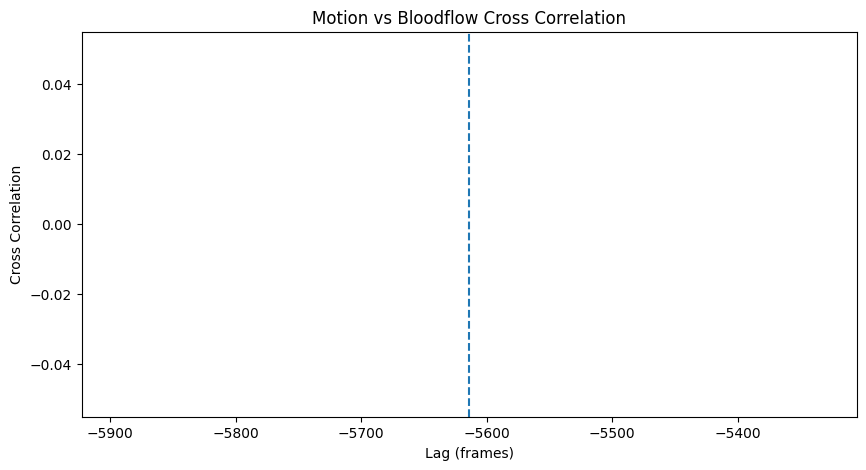

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate

# Load data
df = pd.read_csv("combined_data.csv", index_col=0)

# Separate X and y
X = df.drop(columns=["LDF_bloodflow"])
y = df["LDF_bloodflow"]

# Motion intensity signal
motion = X.diff().abs().sum(axis=1)

# Standardize
motion = (motion - motion.mean()) / motion.std()
bloodflow = (y - y.mean()) / y.std()

# Cross correlation
corr = correlate(motion, bloodflow, mode='full')

# Lags
lags = np.arange(-len(motion)+1, len(bloodflow))

# Best lag
best_lag = lags[np.argmax(corr)]

print("Best lag:", best_lag)
print("Time delay (seconds):", best_lag * 0.1)

# Plot
plt.figure(figsize=(10,5))
plt.plot(lags, corr)
plt.axvline(best_lag, linestyle='--')
plt.xlabel("Lag (frames)")
plt.ylabel("Cross Correlation")
plt.title("Motion vs Bloodflow Cross Correlation")
plt.show()


BEST SHIFT FOUND
shift    61.000000
r2        0.053134
Name: 361, dtype: float64


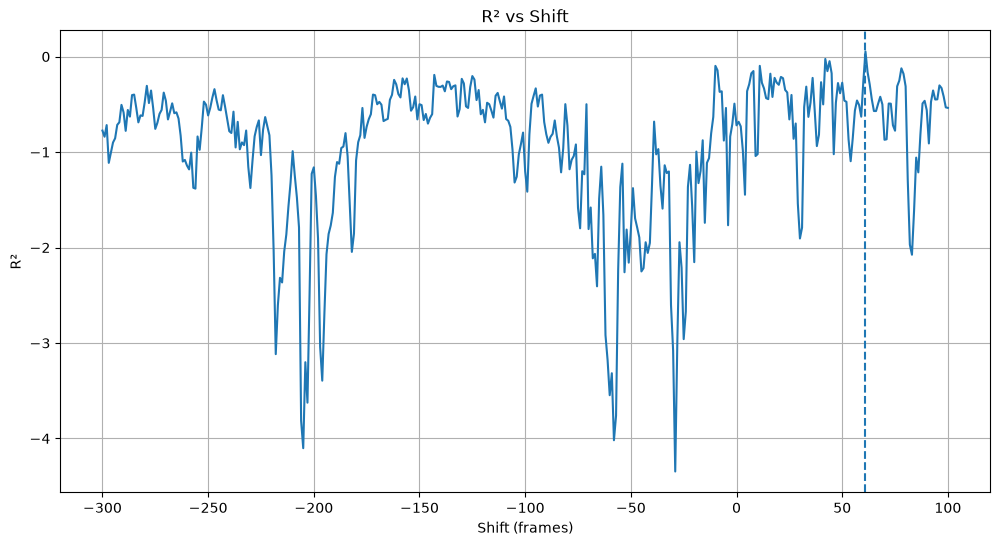

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

odf = pd.read_csv("new_pose_detection/data/angela_final.csv", index_col=0)

results = []

for shift in range(-300, 101):

    df = odf.copy()

    # Apply shift
    df['LDF_bloodflow'] = df['LDF_bloodflow'].shift(-shift)

    # Remove NaNs created by shifting
    df = df.dropna()

    X = df.drop(columns=['LDF_bloodflow'])
    y = df['LDF_bloodflow']

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        shuffle=False
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    preds = model.predict(X_test)

    r2 = r2_score(y_test, preds)

    results.append((shift, r2))

results_df = pd.DataFrame(results, columns=["shift", "r2"])

best_row = results_df.loc[results_df["r2"].idxmax()]

print("\nBEST SHIFT FOUND")
print(best_row)

plt.figure(figsize=(12,6))
plt.plot(results_df["shift"], results_df["r2"])
plt.axvline(best_row["shift"], linestyle="--")
plt.xlabel("Shift (frames)")
plt.ylabel("R²")
plt.title("R² vs Shift")
plt.grid(True)
plt.show()